___
<a href='https://cafe.naver.com/jmhonglab'><p style="text-align:center;"><img src='https://lh3.googleusercontent.com/lY3ySXooSmwsq5r-mRi7uiypbo0Vez6pmNoQxMFhl9fmZJkRHu5lO2vo7se_0YOzgmDyJif9fi4_z0o3ZFdwd8NVSWG6Ea80uWaf3pOHpR4GHGDV7kaFeuHR3yAjIJjDgfXMxsvw=w2400'  class="center" width="50%" height="50%"/></p></a>
___
<center><em>Content Copyright by HongLab, Inc.</em></center>

# 디지털 이미지 다루기

스마트폰의 내장 카메라, 웹캠 등의 디지털 영상 장치의 발달로 인해서 디지털 이미지는 우리에게 매우 친숙합니다. 결과를 쉽게 눈으로 볼 수 있기 때문에 직관적으로 프로그래밍 연습을 할 수 있는 좋은 기회입니다.


### 디지털 이미지의 형식

몇 가지 기본적인 용어를 정리해보겠습니다.
- RGB 컬러: Red, Gree, Blue의 조합으로 색을 표현합니다. [색상 팔레트](https://search.naver.com/search.naver?where=nexearch&sm=top_hty&fbm=1&ie=utf8&query=rgb+%EC%83%89%EC%83%81%ED%91%9C
)를 참고하세요.
- RGBA 컬러: RGB 컬러에 불투명도(opaque)를 의미하는 Alpha를 추가한 것입니다.
- 픽셀(Pixel): PICture ELement의 줄임말로써 디지털 이미지에서 색을 표현하는 작은 면적을 의미합니다.


### [Pillow](https://pillow.readthedocs.io/en/stable/handbook/tutorial.html)를 이용한 이미지 조작

여기서는 기본적인 이미지 조작 방법을 몇 가지 사용해보겠습니다. 더 많은 기능들은 [Handbook](https://pillow.readthedocs.io/en/stable/handbook/index.html)을 참고하세요.

```
pip install pillow
```


다양한 포맷의 이미지들을 쉽게 읽어들일 수 있습니다.

In [1]:
# 예외처리 예시
from PIL import Image

try:
    im = Image.open("NO_IMAGE.jpg")
except OSError:
    print("파일을 읽어들이지 못했습니다.")

파일을 읽어들이지 못했습니다.


In [2]:
# 정상적으로 읽어들인 후 이미지 정보 출력
from PIL import Image

im = Image.open("baldwin_hills.jpg") #Open함수는 이미지 객체를 만들어줌. 이 객체를 im변수에 바인딩(연결)

print(im.format, im.size, im.mode) # JPEG (960, 540) RGB

im

#im.show() # 운영체제를 통해서(운영체제에 등록된 이미지뷰어를 통해서) 이미지를 보여줍니다.

JPEG (960, 540) RGB


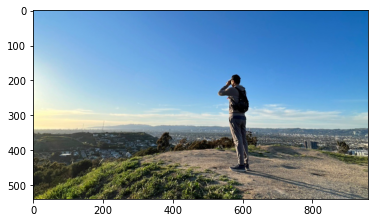

In [3]:
from matplotlib.pyplot import imshow

import numpy as np
from PIL import Image

im = Image.open("baldwin_hills.jpg")

imshow(np.asarray(im)) #이미지를 numpy로 바꾼 다음 앞에서 배운 pilplot으로 그릴 수도 있음

이미지의 해상도를 바꿀 수 있습니다.

In [4]:
# 해상도 줄이기
from PIL import Image

Image.open("baldwin_hills.jpg").resize((48, 27))

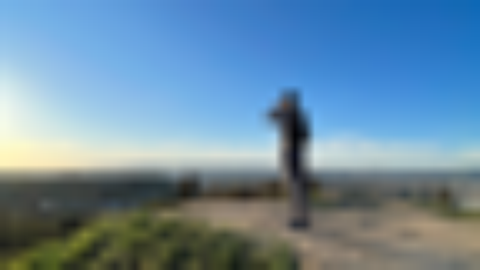

In [5]:
# BILINEAR 필터로 해상도를 다시 키우기
Image.open("baldwin_hills.jpg").resize((48, 27)).resize(
    (480, 270), resample=Image.BILINEAR
) 
#한번 해상도를 줄인 이미지는 resize를 다시 해도 원래처럼 선명해지지 않음

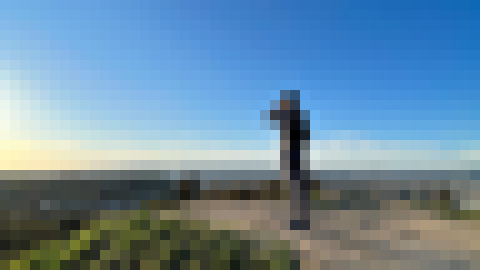

In [6]:
# NEAREST 필터로 해상도를 다시 키우기
Image.open("baldwin_hills.jpg").resize((48, 27)).resize(
    (480, 270), resample=Image.NEAREST
) 

# resize 할 때는 샘플링 방식을 선택할 수 있음. 
# 다양한 샘플링 방식은 Image.resize 공식문서 찾아서 resample 옵션들 테스트해보기

이미지의 일부만 잘라낼(crop) 수도 있습니다.

None (120, 300) RGB


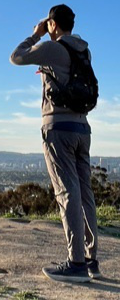

In [7]:
from PIL import Image

cropped = Image.open("baldwin_hills.jpg").crop((520, 180, 640, 480)) #crop에는 정수 4개를 묶은 튜플을 넣어줌

print(cropped.format, cropped.size, cropped.mode) # None (120, 300) RGB

cropped

잘라낸 부분을 다른 곳에 덮어쓸 수도 있습니다.

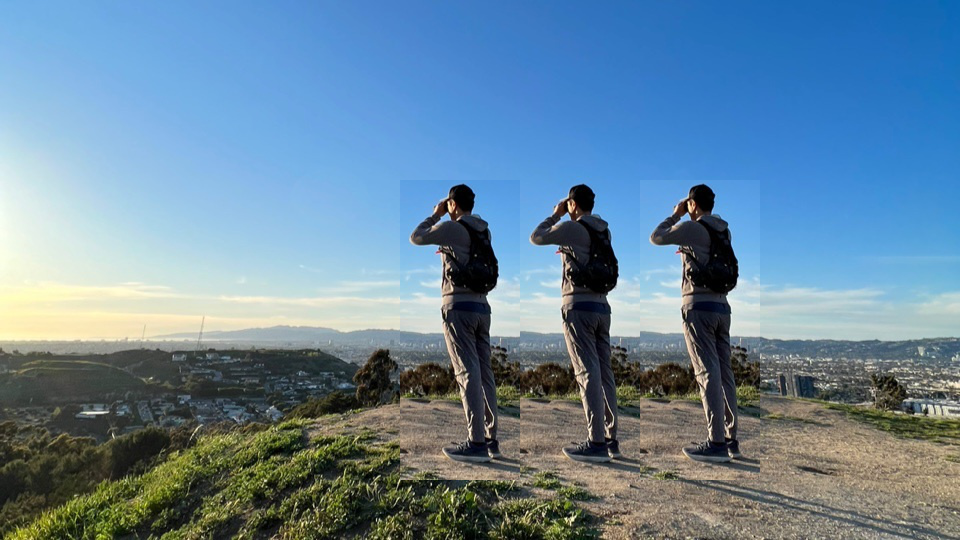

In [12]:
from PIL import Image

im = Image.open("baldwin_hills.jpg")
cropped = im.crop((520, 180, 640, 480))
im.paste(cropped, (400, 180, 520, 480)) # 주의 : im = im.paste(...) -> None
im.paste(cropped, (640, 180, 760, 480))
im


이미지를 격자 형태로 배치해봅시다.

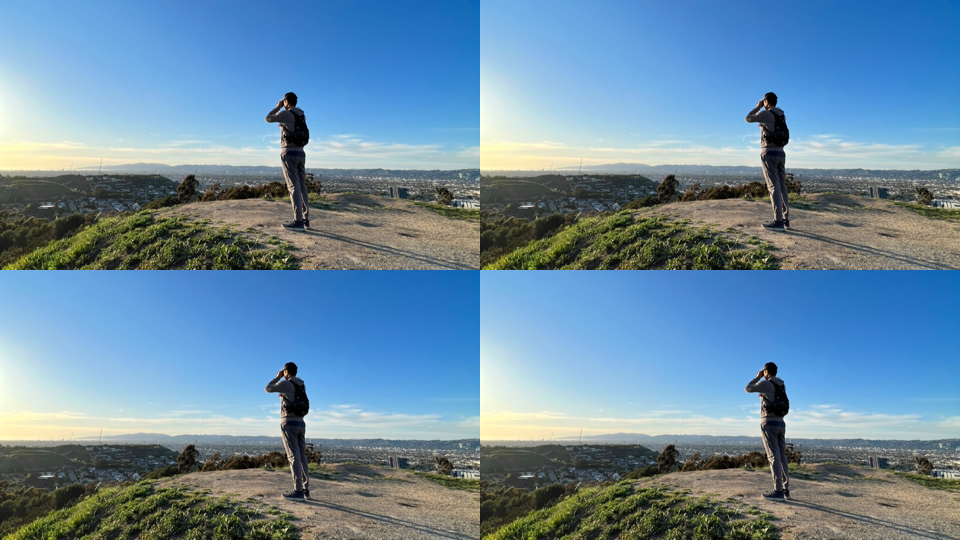

In [20]:
from PIL import Image

src = Image.open("baldwin_hills.jpg").resize((480, 270))

w, h = src.size

dst = Image.new("RGB", (w * 2, h * 2))


# dst.paste(src, (0, 0, 480, 270))
# dst.paste(src, (480, 0, 960, 270))
# dst.paste(src, (0, 270, 480, 540))
# dst.paste(src, (480, 270, 960, 540))
dst.paste(src, (0, 0, w, h))
dst.paste(src, (w, 0, w * 2, h))
dst.paste(src, (0, h, w, h * 2))
dst.paste(src, (w, h, w * 2, h * 2))

dst.save("grid.png") # 이미지 저장

dst

이미지를 회전시킬 수도 있습니다.

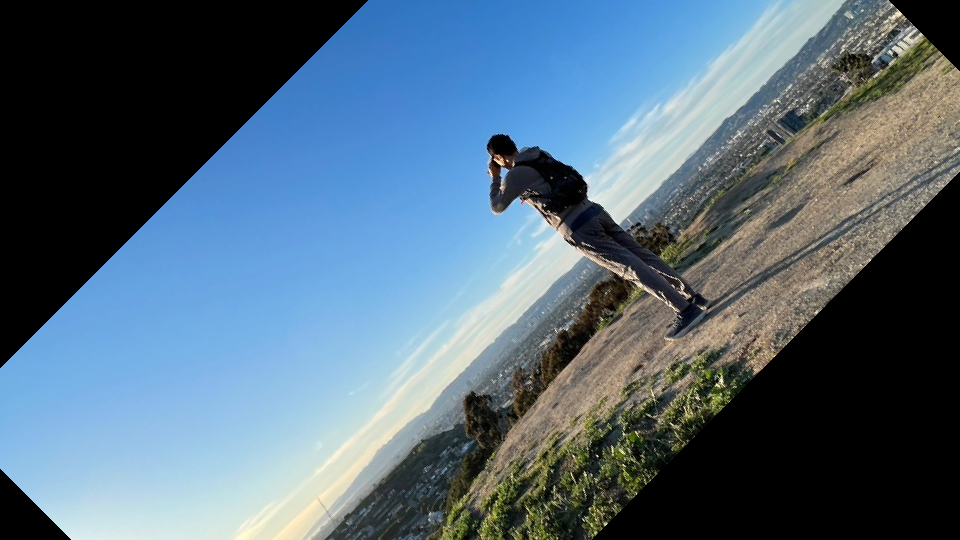

In [5]:
from PIL import Image

# 반시계방향으로 45도 회전
Image.open("baldwin_hills.jpg").rotate(45) # 센터값 설정 안하면 이미지의 중심을 센터값으로 디폴트 

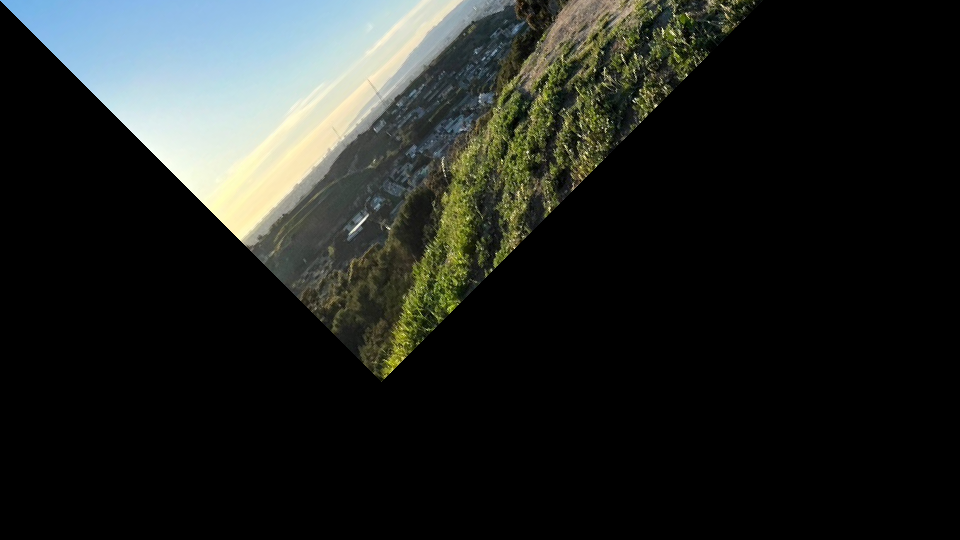

In [22]:
from PIL import Image

# 반시계방향으로 45도 회전
Image.open("baldwin_hills.jpg").rotate(45, center=(0,0)) #좌측상단을 기준으로 반시계방향 회전

다양한 기하학적 변환을 할 수 있습니다.

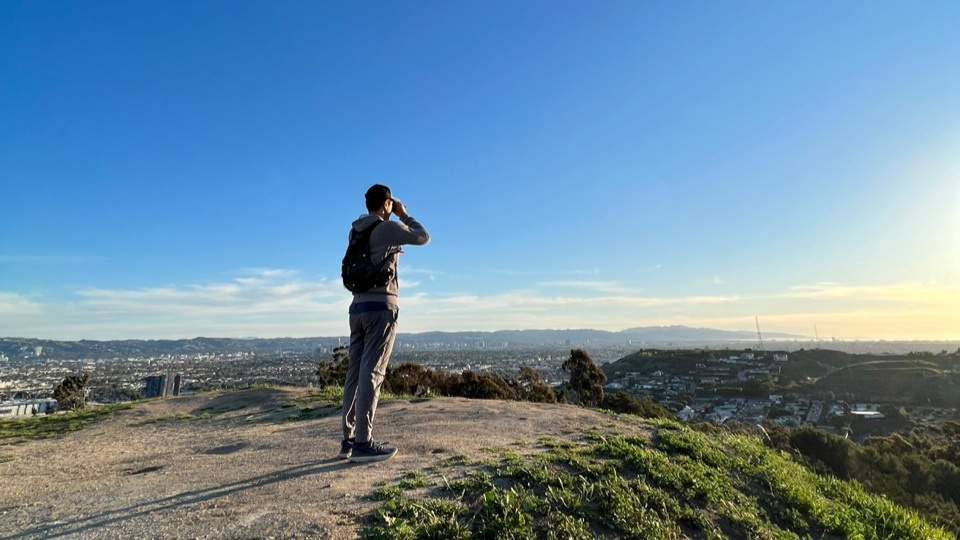

In [7]:
from PIL import Image

im = Image.open("baldwin_hills.jpg")

out = im.transpose(Image.FLIP_LEFT_RIGHT)
# out = im.transpose(Image.FLIP_TOP_BOTTOM)
# out = im.transpose(Image.ROTATE_90)
# out = im.transpose(Image.ROTATE_180)
# out = im.transpose(Image.ROTATE_270)

out

이미지 위에 글을 쓸 수도 있습니다.

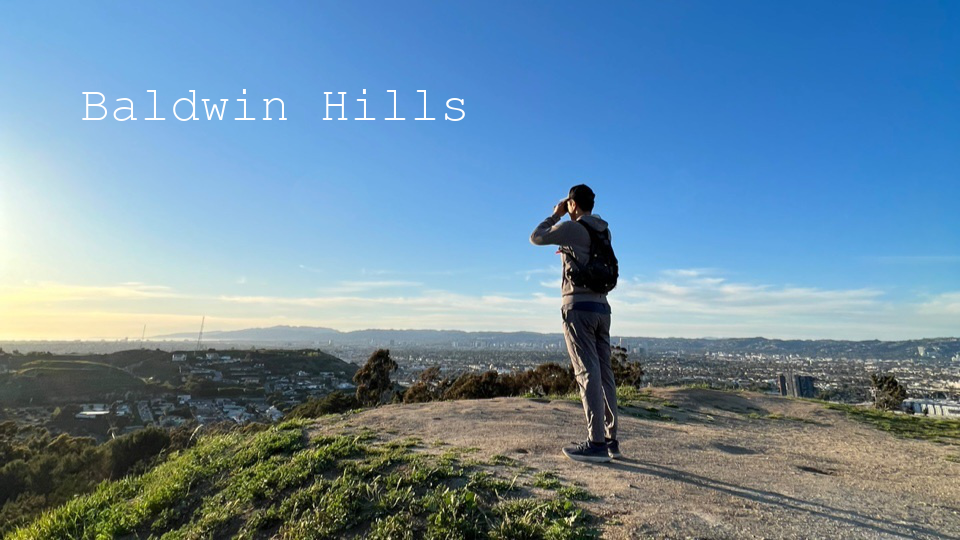

In [27]:
from PIL import Image, ImageDraw, ImageFont

im = Image.open("baldwin_hills.jpg")

fnt = ImageFont.truetype("FreeMono.ttf", 50)

d = ImageDraw.Draw(im)

d.text((80, 80), "Baldwin Hills", fill=(255, 255, 255), font=fnt)

im

[화질 개선(image enhancement) 기능들](https://pillow.readthedocs.io/en/stable/reference/ImageEnhance.html#module-PIL.ImageEnhance)도 사용할 수 있습니다.

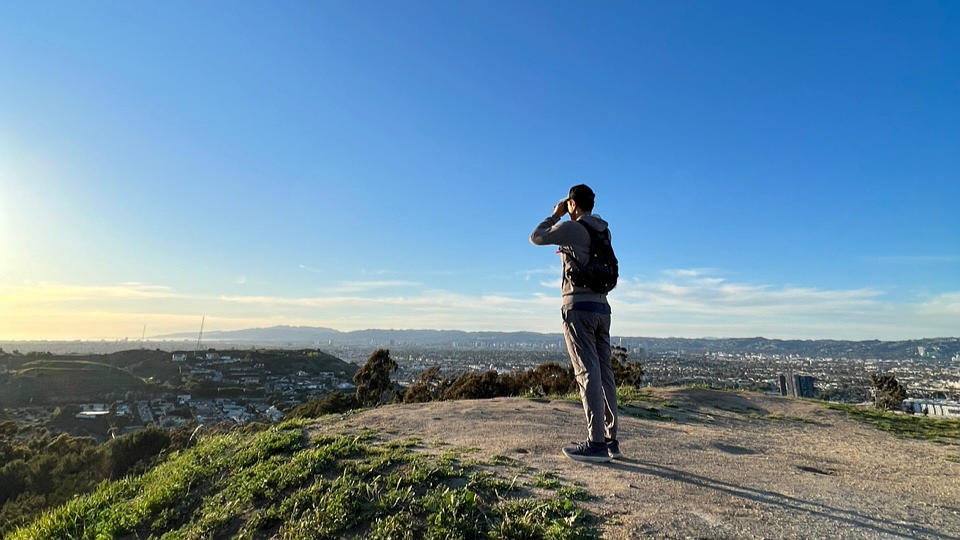

In [29]:
from PIL import Image, ImageEnhance

im = Image.open("baldwin_hills.jpg")

enhancer = ImageEnhance.Sharpness(im)
# enhancer = ImageEnhance.Brightness(im)

im = enhancer.enhance(1.5)

im

간단한 도형을 그릴 수도 있습니다. 더 다양한 기능들은 [여기](https://pillow.readthedocs.io/en/stable/reference/ImageDraw.html)를 참고하세요.

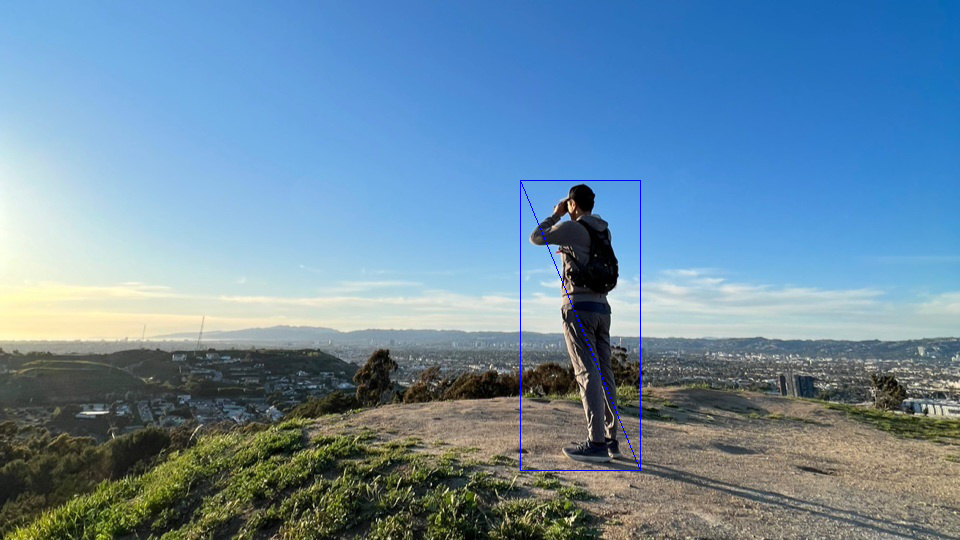

In [32]:
from PIL import Image, ImageDraw

with Image.open("baldwin_hills.jpg") as im:

    draw = ImageDraw.Draw(im)

    x, y, w, h = 520, 180, 120, 290
    draw.line((x, y, x + w, y + h), fill=(0, 0, 255)) # sample

    # 직선 4개로 사각형 그리기 연습
    draw.line((x, y, x, y + h), fill=(0, 0, 255)) # sample
    draw.line((x + w, y, x + w, y + h), fill=(0, 0, 255)) # sample
    draw.line((x, y, x+w, y), fill=(0, 0, 255)) # sample
    draw.line((x, y+h, x+w, y+h), fill=(0, 0, 255)) # sample


im

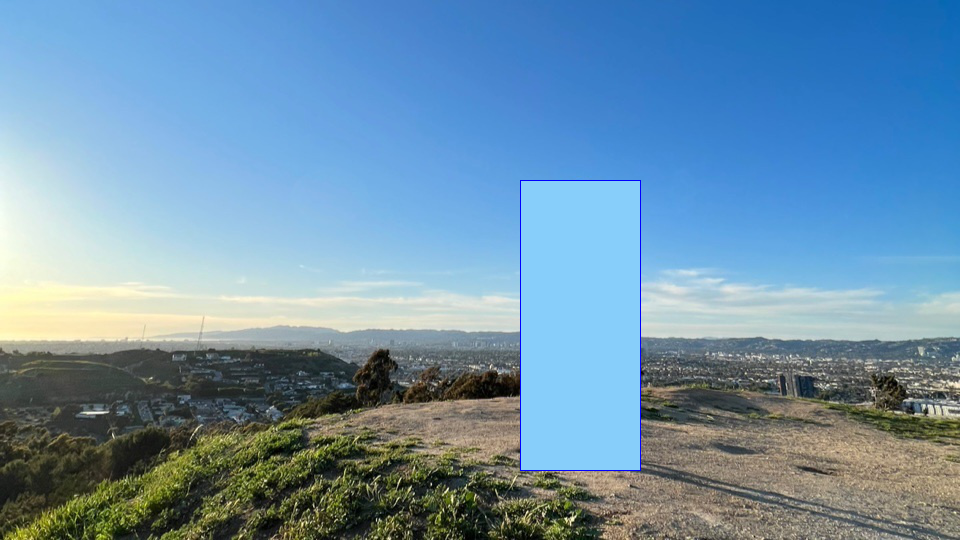

In [33]:
from PIL import Image, ImageDraw

with Image.open("baldwin_hills.jpg") as im:

    draw = ImageDraw.Draw(im)

    x, y, w, h = 520, 180, 120, 290
    draw.rectangle((x, y, x+w, y+h), outline=(0, 0, 255), fill=(135,206,250)) 
    # draw.rounded_rectangle((x, y, x+w, y+h), radius=30, outline(0, 0, 255), fill=(255,255,255))

im

투명도를 사용해봅시다.

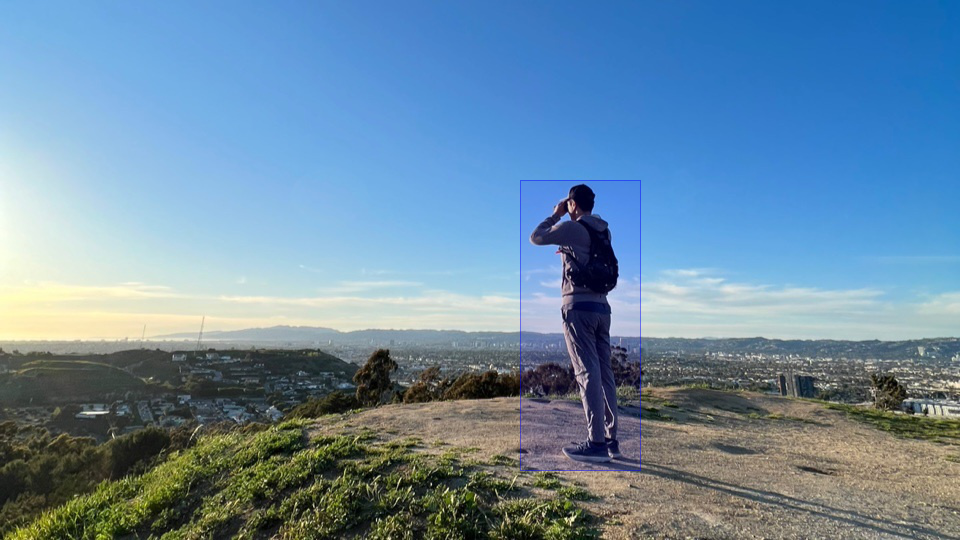

In [34]:
with Image.open("baldwin_hills.jpg").convert("RGBA") as base: #jpg 파일은 RGB 포멧이기 때문에 파일 열면서 RGBA 포멧으로 변환

    # 완전히 투명한 이미지 생성
    overlay = Image.new("RGBA", base.size, (0, 0, 0, 0))

    # 투명 이미지 위에 그리기
    draw = ImageDraw.Draw(overlay)
    draw.rectangle(
        (x, y, x + w, y + h), outline=(0, 0, 255, 128), #alpha = 128
        fill=(0, 0, 255, 30) #alpha = 30
    )

    # 투명도를 이용하여 합성
    comp = Image.alpha_composite(base, overlay)

comp